In [3]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor  
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.model_selection import train_test_split
from scipy.special import expit


In [4]:
# [ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [5]:
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight

In [6]:
print(len(bream_length))
print(len(smelt_length))

35
14


In [7]:
label = ['bream']*35+['smelt']*14
# label

data = [[l,w] for l, w in zip(total_length, total_weight)]
# data

In [8]:
train_data, test_data, train_label, test_label = train_test_split(data,label)


In [9]:
data = np.column_stack((total_length, total_weight))
label = np.concatenate((np.ones(35),np.zeros(14)))

In [10]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [11]:
lr = LogisticRegression()
lr.fit(train_scaled, train_label)

predict = lr.predict(test_scaled)
print('예측 생선 :', predict)

print('train 정확도 :', lr.score(train_scaled, train_label))
print('test 정확도 :', lr.score(test_scaled, test_label))

예측 생선 : ['bream' 'bream' 'bream' 'smelt' 'bream' 'bream' 'bream' 'bream' 'smelt'
 'bream' 'bream' 'bream' 'bream']
train 정확도 : 1.0
test 정확도 : 1.0


In [12]:
lr.predict_proba(test_scaled)[:5]

array([[0.98173617, 0.01826383],
       [0.8153768 , 0.1846232 ],
       [0.98380191, 0.01619809],
       [0.06633011, 0.93366989],
       [0.97117734, 0.02882266]])

In [13]:
decision = lr.decision_function(test_scaled[:5])
np.round(decision,decimals=4)
expit(decision)

array([0.01826383, 0.1846232 , 0.01619809, 0.93366989, 0.02882266])

In [14]:
new = [[21,90]]
new = [[25,150]]

In [15]:
in_data = input('생선의 길이(cm), 무게(g)를 입력하세요: 예)21,90')
in_data = '21,9'
in_data = in_data.split(',')
in_data2 = list(map(float, in_data))
in_data2

[21.0, 9.0]

In [16]:
new_scaled = ss.transform ([[21,90]])
new2_scaled = ss.transform ([[25,150]])

In [17]:
result = lr.predict(new_scaled)
result2 = lr.predict(new2_scaled)
result[0]
p_result = lr.predict_proba(new_scaled)
p_result2 = lr.predict_proba(new2_scaled)
p_result[0][0]
print(f'예측생선 : {result[0]} / ({p_result[0][1]*100:.2f} %)')
print(f'예측생선 : {result2[0]} / ({p_result2[0][0]*100:.2f} %)')

예측생선 : smelt / (62.36 %)
예측생선 : bream / (60.70 %)


In [18]:
train_scaled[:,0]

array([-1.3239983 , -1.26602472,  0.95629555,  1.29447472,  0.85967293,
        0.2799372 ,  0.71473899,  0.85967293,  1.05291817,  0.56980506,
        0.44419566,  1.1978521 ,  0.47318244, -1.45926996, -1.14041532,
       -1.43994544, -1.43028318,  0.81136162, -1.50758127,  0.85967293,
        0.66642768, -1.07277948,  0.47318244,  1.1978521 ,  0.85967293,
       -1.34332282, -1.38197187,  0.76305031, -1.57521711,  0.34757304,
        0.37655982,  0.52149375,  0.34757304,  0.37655982, -1.38197187,
        0.01905613])

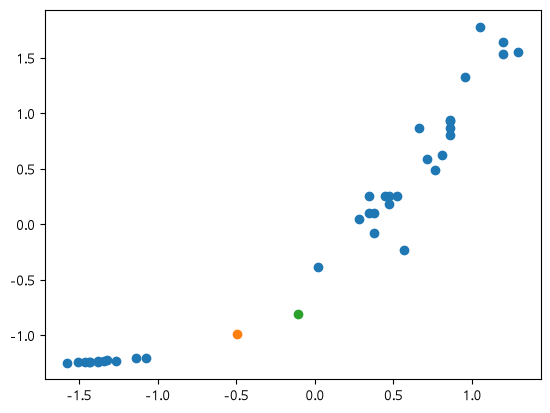

In [19]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])
plt.show()

In [20]:
lr.predict_proba(test_scaled[:5])

array([[0.98173617, 0.01826383],
       [0.8153768 , 0.1846232 ],
       [0.98380191, 0.01619809],
       [0.06633011, 0.93366989],
       [0.97117734, 0.02882266]])

In [21]:
decisions = lr.decision_function(test_scaled[:5])
np.round(decisions,decimals=4)
expit(decisions)

array([0.01826383, 0.1846232 , 0.01619809, 0.93366989, 0.02882266])

In [22]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))

train정확도 :  1.0
test정확도 :  1.0


In [25]:
in_data = input('생선의 길이(cm), 무게(g)를 입력하세요: ')
in_data = in_data.split(',')
in_data = list(map(float, in_data))

in_data_scaled = ss.transform([in_data])
proba = lr.predict_proba(in_data_scaled)

if proba[0][1] >= 0.7:
    print('예측 생선 : 도미(Bream)')
elif proba[0][0] >= 0.7:
    print('예측 생선 : 빙어(Smelt)')
else:
    print('판단하기 어려운 생선입니다.')

판단하기 어려운 생선입니다.


In [24]:
print('입력값:', in_data)
print('정규화값:', ss.transform([in_data]))
print('예측결과:', lr.predict(ss.transform([in_data])))

입력값: [21.0, 90.0]
정규화값: [[-0.49304376 -0.990967  ]]
예측결과: ['smelt']
